# Plot JAXMD benchmark

Average runtime of the reverse-mode gradient for the `jaxmd20` benchmark, per pass pipeline and AD placement.

In [28]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [29]:
# works whether the notebook is run from the repo root or from `results/`
path = Path("results_JAXMD.json")
if not path.exists():
    path = Path("..") / path

# one row per sample (memory is null when xprof recorded no memory profile, e.g. on CPU)
samples = pd.read_json(path).explode(["time_s", "peak_memory_bytes"])
samples = samples.astype({"time_s": float, "peak_memory_bytes": float})
samples

,benchmark,pipeline,backend,key,time_s,peak_memory_bytes
0,jaxmd20,JaXPipe,cuda,Primal,0.000855,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000855,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000852,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000839,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000844,437296640.0
...,...,...,...,...,...,...
32,jaxmd20,IDefOpt,cuda,BothRev,0.001471,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001451,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001445,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001441,172748544.0


In [30]:
# one row per (benchmark, pipeline, backend, key) with the statistics over the samples
df = (
    samples.groupby(["benchmark", "pipeline", "backend", "key"], sort=False)
    .agg(
        nsamples=("time_s", "size"),
        time_avg_s=("time_s", "mean"),
        time_std_s=("time_s", "std"),
        time_min_s=("time_s", "min"),
        time_max_s=("time_s", "max"),
        mem_avg_bytes=("peak_memory_bytes", "mean"),
        mem_std_bytes=("peak_memory_bytes", "std"),
        mem_min_bytes=("peak_memory_bytes", "min"),
        mem_max_bytes=("peak_memory_bytes", "max"),
    )
    .reset_index()
)
df

,benchmark,pipeline,backend,key,nsamples,time_avg_s,time_std_s,time_min_s,time_max_s,mem_avg_bytes,mem_std_bytes,mem_min_bytes,mem_max_bytes
0,jaxmd20,JaXPipe,cuda,Primal,10,0.000843,0.000010,0.000828,0.000855,437296640.0,0.0,437296640.0,437296640.0
1,jaxmd20,Jax,cuda,Primal,10,0.000837,0.000032,0.000820,0.000925,437586176.0,0.0,437586176.0,437586176.0
2,jaxmd20,HLOOpt,cuda,Primal,10,0.000858,0.000031,0.000807,0.000903,169745664.0,0.0,169745664.0,169745664.0
3,jaxmd20,PartOpt,cuda,Primal,10,0.000873,0.000034,0.000847,0.000958,212948480.0,0.0,212948480.0,212948480.0
4,jaxmd20,IPartOpt,cuda,Primal,10,0.000882,0.000052,0.000820,0.000999,212948480.0,0.0,212948480.0,212948480.0
5,jaxmd20,DefOpt,cuda,Primal,10,0.000459,0.000016,0.000446,0.000499,308082688.0,0.0,308082688.0,308082688.0
6,jaxmd20,IDefOpt,cuda,Primal,10,0.000465,0.000010,0.000451,0.000484,169746432.0,0.0,169746432.0,169746432.0
7,jaxmd20,JaXPipe,cuda,Forward,10,0.000779,0.000034,0.000761,0.000876,283132160.0,0.0,283132160.0,283132160.0
8,jaxmd20,Jax,cuda,Forward,10,0.001260,0.000133,0.001150,0.001607,438845952.0,0.0,438845952.0,438845952.0
9,jaxmd20,HLOOpt,cuda,Forward,10,0.000774,0.000046,0.000747,0.000900,171009024.0,0.0,171009024.0,171009024.0


In [31]:
# key -> group label
KEYS = {
    "PreRev": "Pre AD",
    "PostRev": "Post AD",
    "BothRev": "Pre + Post AD",
}

# pass pipeline -> legend label
PIPELINES = {
    "HLOOpt": "HLO Opts.",
    "DefOpt": "All (No Inline)",
    "IDefOpt": "All (Inline)",
}

COLORS = {
    "HLOOpt": "#fc8d62",
    "DefOpt": "#66c2a5",
    "IDefOpt": "#8da0cb",
}

avg = df.pivot_table(index="key", columns="pipeline", values="time_avg_s")  # seconds
baseline = avg.loc["BothRev", "Jax"]  # "No opt"

avg.loc[list(KEYS), list(PIPELINES)].assign(**{"No opt (Jax)": baseline})

pipeline,HLOOpt,DefOpt,IDefOpt,No opt (Jax)
key,,,,
PreRev,0.001371,0.001391,0.001406,0.003755
PostRev,0.003835,0.002736,0.001493,0.003755
BothRev,0.001406,0.001431,0.001463,0.003755


## Runtime

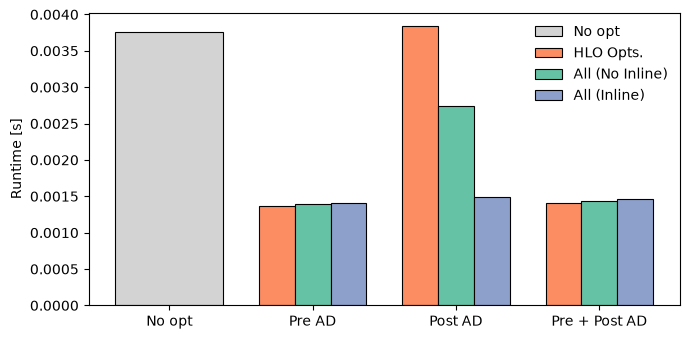

In [32]:
width = 0.25
bar_kw = dict(edgecolor="black", linewidth=0.8)

fig, ax = plt.subplots(figsize=(7, 3.5))

# "No opt" group: single wide bar
ax.bar(0, baseline, width=len(PIPELINES) * width, color="lightgray", label="No opt", **bar_kw)

# Pre AD / Post AD / Pre + Post AD groups
x = np.arange(1, len(KEYS) + 1)
offsets = (np.arange(len(PIPELINES)) - (len(PIPELINES) - 1) / 2) * width
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, avg.loc[list(KEYS), pipe], width, color=COLORS[pipe], label=label, **bar_kw)

ax.set_xticks(np.arange(len(KEYS) + 1), ["No opt", *KEYS.values()])
ax.set_ylabel("Runtime [s]")
ax.legend(frameon=False)
fig.tight_layout()

# fig.savefig("jaxmd20-runtime.pdf", bbox_inches="tight")
plt.show()

### Speedup over JAX

In [33]:
# speedup w.r.t. "No opt" (Jax, BothRev): > 1 means faster than the baseline
speedup = (baseline / avg.loc[list(KEYS), list(PIPELINES)]).rename(index=KEYS, columns=PIPELINES)
speedup.round(2)

pipeline,HLO Opts.,All (No Inline),All (Inline)
key,,,
Pre AD,2.74,2.70,2.67
Post AD,0.98,1.37,2.51
Pre + Post AD,2.67,2.62,2.57


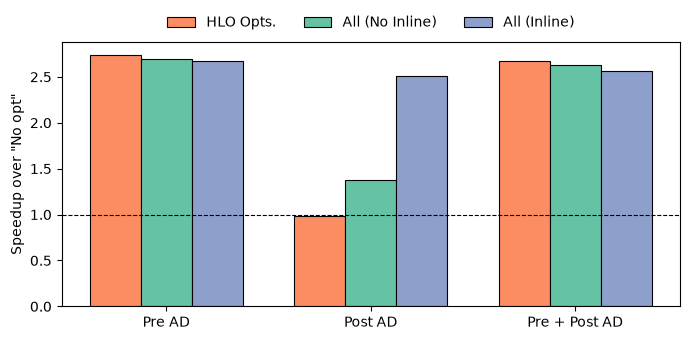

In [34]:
fig, ax = plt.subplots(figsize=(7, 3.5))

x = np.arange(len(KEYS))
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, speedup[label], width, color=COLORS[pipe], label=label, **bar_kw)

ax.axhline(1, color="black", linestyle="--", linewidth=0.8)  # "No opt" baseline
ax.set_xticks(x, list(KEYS.values()))
ax.set_ylabel('Speedup over "No opt"')
ax.legend(frameon=False, ncols=len(PIPELINES), loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()

# fig.savefig("jaxmd20-speedup.pdf", bbox_inches="tight")
plt.show()

## Memory usage

In [35]:
# peak device memory over the samples, in MiB
mem = df.pivot_table(index="key", columns="pipeline", values="mem_avg_bytes") / 2**20
mem_baseline = mem.loc["BothRev", "Jax"]  # "No opt"

mem.loc[list(KEYS), list(PIPELINES)].assign(**{"No opt (Jax)": mem_baseline})

pipeline,HLOOpt,DefOpt,IDefOpt,No opt (Jax)
key,,,,
PreRev,164.838867,164.838867,164.838867,420.143311
PostRev,164.794678,296.608154,164.758789,420.143311
BothRev,164.745850,164.745850,164.745850,420.143311


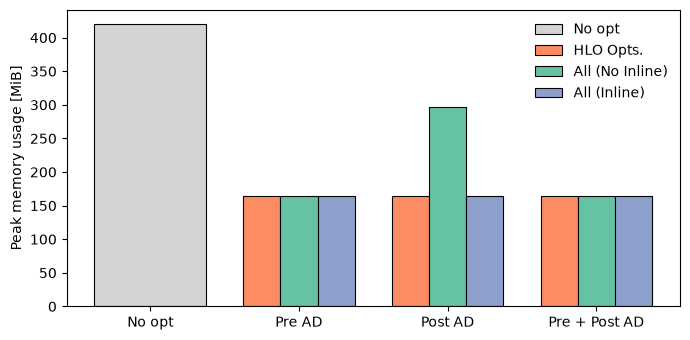

In [36]:
fig, ax = plt.subplots(figsize=(7, 3.5))

# "No opt" group: single wide bar
ax.bar(0, mem_baseline, width=len(PIPELINES) * width, color="lightgray", label="No opt", **bar_kw)

# Pre AD / Post AD / Pre + Post AD groups
x = np.arange(1, len(KEYS) + 1)
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, mem.loc[list(KEYS), pipe], width, color=COLORS[pipe], label=label, **bar_kw)

ax.set_xticks(np.arange(len(KEYS) + 1), ["No opt", *KEYS.values()])
ax.set_ylabel("Peak memory usage [MiB]")
ax.legend(frameon=False)
fig.tight_layout()

# fig.savefig("jaxmd20-memory.pdf", bbox_inches="tight")
plt.show()